# Week 8 Take Home

This week has two parts:

| Part | Lessons | Take-home work |
|------|---------|----------------|
| **A. Grouping & Aggregating Data** | `1-Grouping & Aggregating Data/` (notebooks 1–4) | Project 4 below + the notebook task solutions |
| **B. Data Visualization** | `2-Data Visualization (Seaborn & Matplotlib)/` (videos + scripts) | Re-create the plots from the videos using the Part A milk data: a histogram, a KDE plot, a box/violin plot, a regression plot and a heatmap. Add them at the end of this notebook. |

Part A data comes from the cohort database (schema `week09`). See `Data Access (SQL).md`.

---
# Part A: Grouping & Aggregating Data

## Project 4: Exploring the UK's milk imports and exports

A country's economy depends, sometimes heavily, on its exports and imports. The United Nations Comtrade database provides data on global trade. It will be used to analyse the UK's imports and exports of milk and cream in 2015:

- How much does the UK export and import and is the balance positive (more exports than imports)? 
- Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?
- Which are the regular customers, i.e. which countries buy milk from the UK every month?
- Which countries does the UK both import from and export to?

In [33]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

from pandas import *
%matplotlib inline

## Getting and preparing the data

The data is obtained from the [United Nations Comtrade](http://comtrade.un.org/data/) website, by selecting the following configuration:

- Type of Product: goods
- Frequency: monthly 
- Periods: January to May of 2015
- Reporter: United Kingdom
- Partners: all
- Flows: imports and exports
- HS (as reported) commodity codes: 0401 (Milk and cream, neither concentrated nor sweetened) and 0402 (Milk and cream, concentrated or sweetened)

Clicking on 'Preview' results in a message that the data exceeds 500 rows. Data was downloaded using the *Download CSV* button and the download file renamed appropriately.

In [34]:
LOCATION = 'comtrade_milk_uk_jan_jul_15.csv'

The data can also be downloaded directly from Comtrade using the "View API Call" URL, modified in two ways:

- `max=500` is increased to `max=5000` to make sure all data is loaded,
- `&fmt=csv` is added at the end to obtain the data in CSV format.

In [35]:
# LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=201505%2C201504%2C201503%2C201502%2C201501&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

On reading in the data, the commodity code has to be read as a string, to not lose the leading zero.

In [36]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
milk.tail(2)


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
635,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2213,None,37883,None,None,0
636,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,1588,None,5676,None,None,0


The data only covers the first five months of 2015. Most columns are irrelevant for this analysis, or contain always the same value, like the year and reporter columns. The commodity code is transformed into a short but descriptive text and only the relevant columns are selected.

In [37]:
def milkType(code):
    if code == '0401': # neither concentrated nor sweetened
        return 'unprocessed'
    if code == '0402': # concentrated or sweetened
        return 'processed' 
    return 'unknown'

COMMODITY = 'Milk and cream'
milk[COMMODITY] = milk['Commodity Code'].apply(milkType)
MONTH = 'Period'
PARTNER = 'Partner'
FLOW = 'Trade Flow'
VALUE = 'Trade Value (US$)'
headings = [MONTH, PARTNER, FLOW, COMMODITY, VALUE]
milk = milk[headings]
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
0,201501,World,Imports,unprocessed,14104602
1,201501,World,Exports,unprocessed,26259792
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271


The data contains the total imports and exports per month, under the 'World' partner. Those rows are removed to keep only the per-country data.

In [38]:
milk = milk[milk[PARTNER] != 'World']
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271
5,201501,Belgium,Exports,unprocessed,996031
6,201501,Bulgaria,Exports,unprocessed,191


## Total trade flow

To answer the first question, 'how much does the UK export and import and is the balance positive (more exports than imports)?',
the dataframe is split into two groups: exports from the UK and imports into the UK. The  trade values within each group are summed up to get the total trading.

In [39]:
grouped = milk.groupby([FLOW])
grouped[VALUE].aggregate(sum)

Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64

This shows a trade surplus of over 100 million dollars.

## Main trade partners

To address the second question, 'Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?', the dataframe is split by country instead, and then each group aggregated for the total trade value. This is done separately for imports and exports. The result is sorted in descending order so that the main partners are at the top.

In [40]:
imports = milk[milk[FLOW] == 'Imports']
grouped = imports.groupby([PARTNER])
print('The UK imports from', len(grouped), 'countries.')
print('The 5 biggest exporters to the UK are:')
totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)
totalImports.head()

The UK imports from 21 countries.
The 5 biggest exporters to the UK are:


Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

The export values can be plotted as a bar chart, making differences between countries easier to see.

<Axes: ylabel='Partner'>

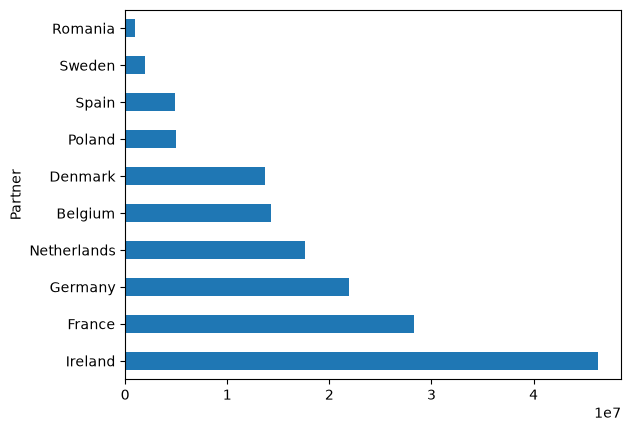

In [41]:
totalImports.head(10).plot(kind='barh')

In [42]:
exports = milk[milk[FLOW] == 'Exports']
grouped = exports.groupby([PARTNER])
print('The UK exports to', len(grouped), 'countries.')
print('The 5 biggest importers from the UK are:')
grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()

The UK exports to 107 countries.
The 5 biggest importers from the UK are:


Partner
Ireland                 128155891
Netherlands              18018603
China                    14111163
Germany                  10828464
China, Hong Kong SAR      9482458
Name: Trade Value (US$), dtype: int64

## Regular importers

Given that there are two commodities, the third question, 'Which are the regular customers, i.e. which countries buy milk from the UK every month?', is meant in the sense that a regular customer imports both commodities every month. This means that if the exports dataframe is grouped by country, each group has exactly ten rows (two commodities bought each of the five months). To see the countries, only the first month of one commodity has to be listed, as by definition it's the same countries every month and for the other commodity.

In [43]:
def buysEveryMonth(group):
    return len(group) == 10

grouped = exports.groupby([PARTNER])
regular = grouped.filter(buysEveryMonth)
regular[(regular[MONTH] == 201501) & (regular[COMMODITY] == 'processed')]

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
268,201501,Belgium,Exports,processed,142610
271,201501,China,Exports,processed,1013141
275,201501,Cyprus,Exports,processed,6625
280,201501,Denmark,Exports,processed,107883
284,201501,France,Exports,processed,178262
287,201501,Germany,Exports,processed,2588380
292,201501,"China, Hong Kong SAR",Exports,processed,1110086
294,201501,Hungary,Exports,processed,2119
298,201501,Ireland,Exports,processed,4020981
300,201501,Italy,Exports,processed,23267


Just over 75% of the total UK exports are due to these regular customers.

In [44]:
regular[VALUE].sum() / exports[VALUE].sum()

np.float64(0.7583526396315317)

## Bi-directional trade

To address the fourth question, 
'Which countries does the UK both import from and export to?', a pivot table is used to list the total export and import value for each country. 

In [45]:
countries = pivot_table(milk, index=[PARTNER], columns=[FLOW], 
                        values=VALUE, aggfunc=sum)
countries.head()

Trade Flow,Exports,Imports
Partner,,
Algeria,8087885.0,NaN
Angola,2416129.0,NaN
Antigua and Barbuda,22218.0,NaN
"Areas, nes",51205.0,NaN
Australia,81644.0,NaN


Removing the rows with a missing value will result in only those countries with bi-directional trade flow with the UK.

In [46]:
countries.dropna()

Trade Flow,Exports,Imports
Partner,,
Austria,56279.0,780.0
Belgium,7209121.0,14325697.0
Czech Rep.,2590.0,486889.0
Denmark,335068.0,13681759.0
France,9381762.0,28314091.0
Germany,10828464.0,21899123.0
Hungary,71378.0,4762.0
Ireland,128155891.0,46263897.0
Italy,173689.0,321635.0


In [47]:
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
milk.head(3)

,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2520,None,3410,None,None,0


In [48]:
milk.info()

<class 'pandas.DataFrame'>
RangeIndex: 1477 entries, 0 to 1476
Data columns (total 35 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Classification          1477 non-null   str   
 1   Year                    1477 non-null   int64 
 2   Period                  1477 non-null   int64 
 3   Period Desc.            1477 non-null   str   
 4   Aggregate Level         1477 non-null   int64 
 5   Is Leaf Code            1477 non-null   int64 
 6   Trade Flow Code         1477 non-null   int64 
 7   Trade Flow              1477 non-null   str   
 8   Reporter Code           1477 non-null   str   
 9   Reporter                1477 non-null   str   
 10  Reporter ISO            0 non-null      object
 11  Partner Code            1477 non-null   str   
 12  Partner                 1477 non-null   str   
 13  Partner ISO             0 non-null      object
 14  2nd Partner Code        0 non-null      object
 15  2nd Partner    

In [49]:
milk.shape

(1477, 35)

In [50]:
milk.columns

Index(['Classification', 'Year', 'Period', 'Period Desc.', 'Aggregate Level',
       'Is Leaf Code', 'Trade Flow Code', 'Trade Flow', 'Reporter Code',
       'Reporter', 'Reporter ISO', 'Partner Code', 'Partner', 'Partner ISO',
       '2nd Partner Code', '2nd Partner', '2nd Partner ISO',
       'Customs Proc. Code', 'Customs', 'Mode of Transport Code',
       'Mode of Transport', 'Commodity Code', 'Commodity', 'Qty Unit Code',
       'Qty Unit', 'Qty', 'Alt Qty Unit Code', 'Alt Qty Unit', 'Alt Qty',
       'Netweight (kg)', 'Gross weight (kg)', 'Trade Value (US$)',
       'CIF Trade Value (US$)', 'FOB Trade Value (US$)', 'Flag'],
      dtype='str')

In [51]:
summary = run_query("""
    SELECT [Trade Flow], [Commodity Code], SUM([Trade Value (US$)]) AS total_value
    FROM week09.comtrade_milk_uk_monthly_14
    GROUP BY [Trade Flow], [Commodity Code]
    ORDER BY total_value DESC
""")
summary

,Trade Flow,Commodity Code,total_value
0,Exports,0402,929722573
1,Exports,0401,867581317
2,Imports,0402,683554344
3,Imports,0401,444215541


In [52]:
monthly = run_query("""
    SELECT [Period], SUM([Trade Value (US$)]) AS exports
    FROM week09.comtrade_milk_uk_monthly_14
    WHERE [Trade Flow] = 'Exports'
    GROUP BY [Period]
    ORDER BY [Period]
""")

In [53]:
milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
pivot = milk.pivot_table(
    index="Period",
    columns="Trade Flow",
    values="Trade Value (US$)",
    aggfunc="sum",
)

In [54]:
summary.to_csv("milk_trade_summary.csv", index=False)

## Provide `1-Grouping & Aggregating Data/1.ipynb` Tasks Solutions below (Execute them)

In [55]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [56]:
%pip install pandas-datareader

Note: you may need to restart the kernel to use updated packages.


In [57]:
if pd.__version__.startswith('0.23'):
    # this solves an incompatibility between pandas 0.23 and datareader 0.6
    # taken from https://stackoverflow.com/questions/50394873/
    core.common.is_list_like = api.types.is_list_like

from pandas_datareader.wb import download

In [58]:
?download

Signature:
download(
    country=None,
    indicator=None,
    start=2003,
    end=2005,
    freq=None,
    errors='warn',
    **kwargs,
)
Docstring:
Download data series from the World Bank's World Development Indicators

Parameters
----------
indicator: string or list of strings
    taken from the ``id`` field in ``WDIsearch()``
country: string or list of strings.
    ``all`` downloads data for all countries
    2 or 3 character ISO country codes select individual
    countries (e.g.``US``,``CA``) or (e.g.``USA``,``CAN``).  The codes
    can be mixed.

    The two ISO lists of countries, provided by wikipedia, are hardcoded
    into pandas as of 11/10/2014.
start: int
    First year of the data series
end: int
    Last year of the data series (inclusive)
freq: str
    frequency or periodicity of the data to be retrieved (e.g. 'M' for
    monthly, 'Q' for quarterly, and 'A' for annual). None defaults to
    annual.
errors: str {'ignore', 'warn', 'raise'}, default 'warn'
    Country co

In [59]:
LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=2014&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

In [60]:
COLUMNS = ['Year', 'Period','Trade Flow','Reporter', 'Partner', 'Commodity','Commodity Code','Trade Value (US$)']
milk = milk[COLUMNS]

In [61]:
milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']

In [62]:
milk_countries.to_csv('countrymilk.csv', index=False)

In [63]:
load_test = run_query("SELECT * FROM week09.countrymilk")
load_test.head(2)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
0,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
1,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316


In [64]:
milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports=milk_world[milk_world['Trade Flow'] == 'Imports']

In [65]:
milkImportsInJanuary2014 = milk_countries_imports[milk_countries_imports['Period'] == 201401]
milkImportsInJanuary2014.sort_values('Trade Value (US$)',ascending=False).head(10)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138
626,2014,201401,Imports,United Kingdom,France,"Milk and cream, concentrated or sweetened",0402,8020014
637,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, concentrated or sweetened",0402,5966962
650,2014,201401,Imports,United Kingdom,Netherlands,"Milk and cream, concentrated or sweetened",0402,4650774
629,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, concentrated or sweetened",0402,4545873
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
612,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, concentrated or sweetened",0402,3584038
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
667,2014,201401,Imports,United Kingdom,Spain,"Milk and cream, concentrated or sweetened",0402,1850097
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872


In [66]:
import os

os.listdir()

['.gitignore',
 'bar_2.png',
 'cities_mean_temp.csv',
 'countrymilk.csv',
 'db',
 'hist.png',
 'img_2.png',
 'img_3.png',
 'london_2014_clean.csv',
 'london_2023_wunderground.csv',
 'milk_trade_summary.csv',
 'nigeria_2023_petroleum.csv',
 'pie.png',
 'wb_gdp_2013.csv',
 'wb_le_2013.csv',
 'wb_pop_2013.csv',
 'Week 6 Take Home.ipynb',
 'Week 7 Take Home.ipynb',
 'Week-8 Take Home.ipynb']

In [67]:
import pandas as pd

fuel = pd.read_csv('nigeria_2023_petroleum.csv', dtype={'cmdCode': str}, index_col=False)
print(fuel.shape)
print(fuel['flowCode'].value_counts())
print(fuel['period'].nunique())
fuel[['period', 'flowCode', 'flowDesc', 'partnerDesc', 'primaryValue']].head()

(366, 47)
flowCode
M    329
X     37
Name: count, dtype: int64
12


,period,flowCode,flowDesc,partnerDesc,primaryValue
0,202312,M,Import,World,1.396964e+09
1,202304,M,Import,Austria,1.492370e+02
2,202308,M,Import,Belgium,5.693768e+08
3,202312,M,Import,Brazil,1.995737e+07
4,202308,M,Import,Canada,5.632600e+04


In [68]:
fuel_countries = fuel[fuel['partnerDesc'] != 'World']

In [69]:
print(fuel_countries.shape)

(342, 47)


In [70]:
fuel_countries['partnerDesc'].unique()

<StringArray>
[             'Austria',              'Belgium',               'Brazil',
               'Canada',                'China',           'Costa Rica',
               'Cyprus',              'Denmark',              'Estonia',
              'Finland',               'France',              'Germany',
                'Ghana',               'Greece',              'Iceland',
            'Indonesia',                 'Iraq',              'Ireland',
               'Israel',                'Italy',        'Côte d'Ivoire',
                'Japan',                'Kenya',        'Rep. of Korea',
              'Lebanon',               'Latvia',            'Lithuania',
           'Luxembourg',             'Malaysia',                'Malta',
            'Mauritius',      'Other Asia, nes',                 'Oman',
              'Namibia',          'Netherlands',                'Niger',
               'Norway',               'Poland',             'Portugal',
   'Russian Federation',         'Sau

In [71]:
fuel_countries['partnerDesc'].eq('World').sum()

np.int64(0)

In [72]:
NOT_COUNTRIES = ['Areas, nes', 'Other Asia, nes']
named = fuel_countries[~fuel_countries['partnerDesc'].isin(NOT_COUNTRIES)]

named_imports = named[named['flowCode'] == 'M']
named_exports = named[named['flowCode'] == 'X']

print('Imports from', named_imports['partnerDesc'].nunique(), 'named countries')
print('Exports to', named_exports['partnerDesc'].nunique(), 'named countries')

Imports from 55 named countries
Exports to 7 named countries


In [73]:
fuel_imports = fuel_countries[fuel_countries['flowCode'] == 'M']

In [74]:
fuel_exports = fuel_countries[fuel_countries['flowCode'] == 'X']

In [75]:
print("Imports:", fuel_imports.shape)
print("Exports:", fuel_exports.shape)

Imports: (317, 47)
Exports: (25, 47)


In [76]:
print(fuel_imports['flowCode'].unique())
print(fuel_exports['flowCode'].unique())

<StringArray>
['M']
Length: 1, dtype: str
<StringArray>
['X']
Length: 1, dtype: str


In [77]:
import_partners = (
    fuel_imports.groupby('partnerDesc')['primaryValue']
    .sum()
    .sort_values(ascending=False)
)

import_partners.head(10)

partnerDesc
Belgium               5.294860e+09
Netherlands           2.833236e+09
India                 2.347662e+09
Malta                 1.920412e+09
Russian Federation    1.237551e+09
Rep. of Korea         1.187947e+09
Saudi Arabia          1.024041e+09
Norway                7.614488e+08
United Kingdom        4.750245e+08
Oman                  4.201558e+08
Name: primaryValue, dtype: float64

In [78]:
export_partners = (
    fuel_exports.groupby('partnerDesc')['primaryValue']
    .sum()
    .sort_values(ascending=False)
)

export_partners.head(10)

partnerDesc
Areas, nes     4.125413e+07
Portugal       2.229100e+07
Netherlands    2.142305e+07
Togo           1.746893e+07
USA            7.842311e+06
Ghana          8.176641e+04
China          4.945926e+03
Mauritius      4.751173e+03
Name: primaryValue, dtype: float64

In [79]:
export_partners = (
    named_exports.groupby('partnerDesc')['primaryValue']
    .sum()
    .sort_values(ascending=False)
)

export_partners.head(10)

partnerDesc
Portugal       2.229100e+07
Netherlands    2.142305e+07
Togo           1.746893e+07
USA            7.842311e+06
Ghana          8.176641e+04
China          4.945926e+03
Mauritius      4.751173e+03
Name: primaryValue, dtype: float64

In [80]:
print(fuel_exports['period'].value_counts().sort_index())

period
202301    1
202302    2
202303    2
202304    1
202305    4
202306    2
202307    1
202308    2
202309    2
202310    3
202311    1
202312    4
Name: count, dtype: int64


In [81]:
fuel_exports['isAggregate'].value_counts(dropna=False)

isAggregate
True    25
Name: count, dtype: int64

In [82]:
fuel_exports[
    ['period', 'partnerDesc', 'primaryValue', 'isAggregate']
].sort_values(by='primaryValue', ascending=False)

,period,partnerDesc,primaryValue,isAggregate
216,202310,Netherlands,2.142305e+07,True
229,202305,Portugal,1.196453e+07,True
39,202306,Portugal,1.032647e+07,True
345,202305,USA,7.842311e+06,True
362,202312,"Areas, nes",7.480434e+06,True
299,202309,Togo,7.151280e+06,True
363,202311,"Areas, nes",6.997258e+06,True
364,202310,"Areas, nes",4.491591e+06,True
50,202312,Togo,4.394663e+06,True
365,202309,"Areas, nes",4.148517e+06,True


In [83]:
fuel_imports['isAggregate'].value_counts(dropna=False)

isAggregate
True    317
Name: count, dtype: int64

In [84]:
fuel_countries.duplicated(
    subset=['period', 'flowCode', 'partnerDesc']
).sum()

np.int64(0)

In [85]:
print("Total imports:", fuel_imports['primaryValue'].sum())
print("Total exports:", fuel_exports['primaryValue'].sum())

Total imports: 20113255623.542
Total exports: 110370880.392


In [86]:
print(countries.groupby(FLOW)[VALUE].sum())
print(world.groupby(FLOW)[VALUE].sum())

KeyError: 'Trade Flow'

In [ ]:
countries_only = countries[countries[PARTNER] != 'Areas, nes']
imports = countries_only[countries_only[FLOW] == 'Import']
exports = countries_only[countries_only[FLOW] == 'Export']

# Regular customers: partners with export records in all 12 months
months_per_partner = exports.groupby(PARTNER)[MONTH].nunique()
print(months_per_partner.sort_values(ascending=False))
print(months_per_partner[months_per_partner == 12])

# Bi-directional trade
both = pd.pivot_table(countries_only, index=PARTNER, columns=FLOW,
                      values=VALUE, aggfunc='sum').dropna()
print(both)

partnerDesc
Togo           4
Ghana          3
Portugal       2
China          1
Mauritius      1
Netherlands    1
USA            1
Name: period, dtype: int64
Series([], Name: period, dtype: int64)
flowDesc           Export        Import
partnerDesc                            
China        4.945926e+03  1.007895e+06
Ghana        8.176641e+04  1.645285e+05
Mauritius    4.751173e+03  1.209219e+05
Netherlands  2.142305e+07  2.833236e+09
Togo         1.746893e+07  1.312915e+08
USA          7.842311e+06  2.378619e+08


## Provide `1-Grouping & Aggregating Data/2.ipynb` Tasks Solutions below (Execute them)

In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [ ]:
if pd.__version__.startswith('0.23'):
    # this solves an incompatibility between pandas 0.23 and datareader 0.6
    # taken from https://stackoverflow.com/questions/50394873/
    core.common.is_list_like = api.types.is_list_like

from pandas_datareader.wb import download

In [ ]:
?download

Signature:
download(
    country=None,
    indicator=None,
    start=2003,
    end=2005,
    freq=None,
    errors='warn',
    **kwargs,
)
Docstring:
Download data series from the World Bank's World Development Indicators

Parameters
----------
indicator: string or list of strings
    taken from the ``id`` field in ``WDIsearch()``
country: string or list of strings.
    ``all`` downloads data for all countries
    2 or 3 character ISO country codes select individual
    countries (e.g.``US``,``CA``) or (e.g.``USA``,``CAN``).  The codes
    can be mixed.

    The two ISO lists of countries, provided by wikipedia, are hardcoded
    into pandas as of 11/10/2014.
start: int
    First year of the data series
end: int
    Last year of the data series (inclusive)
freq: str
    frequency or periodicity of the data to be retrieved (e.g. 'M' for
    monthly, 'Q' for quarterly, and 'A' for annual). None defaults to
    annual.
errors: str {'ignore', 'warn', 'raise'}, default 'warn'
    Country co

In [ ]:
YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdp = download(indicator=GDP_INDICATOR, country=['GB','CN'],
start=YEAR-5, end=YEAR)
gdp = gdp.reset_index()
gdp

,country,year,NY.GDP.MKTP.CD
0,China,2013,9.743124e+12
1,China,2012,8.673665e+12
2,China,2011,7.671757e+12
3,China,2010,6.192565e+12
4,China,2009,5.189577e+12
5,China,2008,4.667346e+12
6,United Kingdom,2013,2.796908e+12
7,United Kingdom,2012,2.719716e+12
8,United Kingdom,2011,2.675590e+12
9,United Kingdom,2010,2.496741e+12


In [ ]:
gdp.groupby('country')['NY.GDP.MKTP.CD'].aggregate(sum)

country
China             4.213803e+13
United Kingdom    1.606357e+13
Name: NY.GDP.MKTP.CD, dtype: float64

In [ ]:
gdp.groupby('year')['NY.GDP.MKTP.CD'].aggregate(sum)

year
2008    7.612598e+12
2009    7.618935e+12
2010    8.689306e+12
2011    1.034735e+13
2012    1.139338e+13
2013    1.254003e+13
Name: NY.GDP.MKTP.CD, dtype: float64

In [ ]:
LOCATION='comtrade_milk_uk_monthly_14.csv'

In [ ]:
LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=2014&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

In [ ]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
# Commodity/Reporter codes are already stored as text (e.g. '0401'), so no dtype needed.
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_monthly_14")
milk.head(3)

,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,...,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2520,None,3410,None,None,0


In [ ]:
COLUMNS = ['Year', 'Period','Trade Flow','Reporter', 'Partner', 'Commodity','Commodity Code','Trade Value (US$)']
milk = milk[COLUMNS]

In [ ]:
milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']

In [ ]:
milk_countries.to_csv('countrymilk.csv', index=False)

In [ ]:
load_test = run_query("SELECT * FROM week09.countrymilk")
load_test.head(2)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
0,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
1,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316


In [ ]:
milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports=milk_world[milk_world['Trade Flow'] == 'Imports']

In [ ]:
milkImportsInJanuary2014 = milk_countries_imports[milk_countries_imports['Period'] == 201401]
milkImportsInJanuary2014.sort_values('Trade Value (US$)',ascending=False).head(10)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138
626,2014,201401,Imports,United Kingdom,France,"Milk and cream, concentrated or sweetened",0402,8020014
637,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, concentrated or sweetened",0402,5966962
650,2014,201401,Imports,United Kingdom,Netherlands,"Milk and cream, concentrated or sweetened",0402,4650774
629,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, concentrated or sweetened",0402,4545873
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
612,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, concentrated or sweetened",0402,3584038
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
667,2014,201401,Imports,United Kingdom,Spain,"Milk and cream, concentrated or sweetened",0402,1850097
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872


In [ ]:
groups = milk_countries.groupby('Trade Flow')

In [ ]:
groups.get_group('Imports').head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
10,2014,201401,Imports,United Kingdom,Denmark,"Milk and cream, neither concentrated nor sweet...",0401,2233438
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872
17,2014,201401,Imports,United Kingdom,Germany,"Milk and cream, neither concentrated nor sweet...",0401,1028700
23,2014,201401,Imports,United Kingdom,Ireland,"Milk and cream, neither concentrated nor sweet...",0401,10676138


In [ ]:
GROUPING_COMMFLOW = ['Commodity Code','Trade Flow']

groups = milk_countries.groupby(GROUPING_COMMFLOW)
groups.groups.keys()

dict_keys([('0401', 'Exports'), ('0401', 'Imports'), ('0402', 'Exports'), ('0402', 'Imports')])

In [ ]:
GROUPING_PARTNERFLOW = ['Partner','Trade Flow']
groups = milk_countries.groupby(GROUPING_PARTNERFLOW)

GROUP_PARTNERFLOW= ('France','Imports')
groups.get_group( GROUP_PARTNERFLOW )

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
15,2014,201401,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1522872
68,2014,201402,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1444455
120,2014,201403,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1414291
171,2014,201404,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1912257
223,2014,201405,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1638838
273,2014,201406,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1449614
327,2014,201407,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,2096771
370,2014,201408,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1474883
416,2014,201409,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1259777
466,2014,201410,Imports,United Kingdom,France,"Milk and cream, neither concentrated nor sweet...",0401,1483422


In [ ]:
groups = milk_countries.groupby(['Commodity Code'])

groups.groups.keys()

C:\Users\kosia\AppData\Local\Temp\ipykernel_13880\1373495997.py:3: Pandas4Warning: In a future version, the keys of `groups` will be a tuple with a single element, e.g. (Commodity Code,) , instead of a scalar, e.g. Commodity Code, when grouping by a list with a single element. Use ``df.groupby(by='a').groups`` instead of ``df.groupby(by=['a']).groups`` to avoid this warning
  groups.groups.keys()


dict_keys(['0401', '0402'])

In [ ]:
milk_countries['Commodity Code'].dtype

<StringDtype(storage='python', na_value=nan)>

In [ ]:
milk_countries['Commodity Code'].unique()

<StringArray>
['0401', '0402']
Length: 2, dtype: str

In [ ]:
print(milk_countries['Commodity Code'].unique())
print(list(groups.groups.keys()))

<StringArray>
['0401', '0402']
Length: 2, dtype: str
['0401', '0402']


C:\Users\kosia\AppData\Local\Temp\ipykernel_13880\2356393621.py:2: Pandas4Warning: In a future version, the keys of `groups` will be a tuple with a single element, e.g. (Commodity Code,) , instead of a scalar, e.g. Commodity Code, when grouping by a list with a single element. Use ``df.groupby(by='a').groups`` instead of ``df.groupby(by=['a']).groups`` to avoid this warning
  print(list(groups.groups.keys()))


In [ ]:
groups = milk_countries.groupby('Commodity Code')

groups.get_group('0402').sort_values(
    'Trade Value (US$)',
    ascending=False
).head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
954,2014,201406,Exports,United Kingdom,Algeria,"Milk and cream, concentrated or sweetened",0402,22411564
880,2014,201405,Exports,United Kingdom,Algeria,"Milk and cream, concentrated or sweetened",0402,19656679
811,2014,201404,Exports,United Kingdom,Algeria,"Milk and cream, concentrated or sweetened",0402,14875816
841,2014,201404,Exports,United Kingdom,Ireland,"Milk and cream, concentrated or sweetened",0402,11712344
773,2014,201403,Exports,United Kingdom,Ireland,"Milk and cream, concentrated or sweetened",0402,11015471


In [ ]:
fuel_groups = fuel_countries.groupby('cmdCode')

fuel_groups.groups.keys()

dict_keys(['2710'])

In [ ]:
fuel_2710.groupby('partnerDesc')['primaryValue'].sum().sort_values(
    ascending=False
).head(10)

partnerDesc
Belgium               5.294860e+09
Netherlands           2.854659e+09
India                 2.347662e+09
Malta                 1.920412e+09
Russian Federation    1.237551e+09
Rep. of Korea         1.187947e+09
Saudi Arabia          1.024041e+09
Norway                7.614488e+08
United Kingdom        4.750245e+08
Oman                  4.201558e+08
Name: primaryValue, dtype: float64

In [ ]:
fuel_groups = fuel_countries.groupby(
    ['flowDesc', 'cmdCode', 'refYear']
)

fuel_groups.groups.keys()

dict_keys([('Export', '2710', 2023), ('Import', '2710', 2023)])

In [ ]:
# 1. Group by commodity code

commodity_totals = (
    fuel_countries
    .groupby(['cmdCode', 'partnerDesc'])['primaryValue']
    .sum()
    .reset_index()
)

print("Top partners by commodity:")
print(
    commodity_totals
    .sort_values('primaryValue', ascending=False)
    .groupby('cmdCode')
    .head(5)
)


# 2. Group by trade flow, commodity and year

GROUPING = ['flowDesc', 'cmdCode', 'refYear']

trade_totals = (
    fuel_countries
    .groupby(GROUPING + ['partnerDesc'])['primaryValue']
    .sum()
    .reset_index()
)

top_partners = (
    trade_totals
    .sort_values(
        GROUPING + ['primaryValue'],
        ascending=[True, True, True, False]
    )
    .groupby(GROUPING)
    .head(1)
)

print("\nTop trade partner in each group:")
print(top_partners)

Top partners by commodity:
   cmdCode         partnerDesc  primaryValue
2     2710             Belgium  5.294860e+09
34    2710         Netherlands  2.854659e+09
18    2710               India  2.347662e+09
31    2710               Malta  1.920412e+09
42    2710  Russian Federation  1.237551e+09

Top trade partner in each group:
  flowDesc cmdCode  refYear partnerDesc  primaryValue
0   Export    2710     2023  Areas, nes  4.125413e+07
9   Import    2710     2023     Belgium  5.294860e+09


## Provide `1-Grouping & Aggregating Data/3.ipynb` Tasks Solutions below (Execute them)

In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [ ]:
data=[['A',10],['A',15],['A',5],['A',20],
['B',10],['B',10],['B',5],
['C',20],['C',30]]

df = pd.DataFrame(data=data, columns=["Commodity","Amount"])
df

,Commodity,Amount
0,A,10
1,A,15
2,A,5
3,A,20
4,B,10
5,B,10
6,B,5
7,C,20
8,C,30


In [ ]:
grouped = df.groupby('Commodity')

In [ ]:
grouped.groups.keys()

dict_keys(['A', 'B', 'C'])

In [ ]:
grouped.get_group('B')

,Commodity,Amount
4,B,10
5,B,10
6,B,5


In [ ]:
# First, add a Year column to the dataframe
df['Year'] = [2014, 2014, 2015, 2015, 2014, 2015, 2015, 2014, 2015]

# Now group by both Commodity and Year
grouped = df.groupby(['Commodity', 'Year'])

In [ ]:
grouped.get_group( ('A',2014) )

,Commodity,Amount,Year
0,A,10,2014
1,A,15,2014


In [ ]:
data = [
    ['A', 10], ['A', 15], ['A', 5], ['A', 20],
    ['B', 10], ['B', 10], ['B', 5],
    ['C', 20], ['C', 30]
]

df = pd.DataFrame(data=data, columns=['Commodity', 'Amount'])

In [ ]:
grouped = df.groupby('Commodity')

In [ ]:
summary = df.groupby('Commodity')['Amount'].sum().reset_index()

summary

,Commodity,Amount
0,A,50
1,B,25
2,C,50


In [ ]:
df['Year'] = [2014, 2014, 2015, 2015, 2014, 2015, 2015, 2014, 2015]

df

,Commodity,Amount,Year
0,A,10,2014
1,A,15,2014
2,A,5,2015
3,A,20,2015
4,B,10,2014
5,B,10,2015
6,B,5,2015
7,C,20,2014
8,C,30,2015


In [ ]:
grouped = df.groupby(['Commodity', 'Year'])

grouped.groups.keys()

dict_keys([('A', 2014), ('A', 2015), ('B', 2014), ('B', 2015), ('C', 2014), ('C', 2015)])

In [ ]:
grouped.get_group(('A', 2014))

,Commodity,Amount,Year
0,A,10,2014
1,A,15,2014


In [ ]:
summary = (
    df.groupby(['Commodity', 'Year'])['Amount']
    .sum()
    .reset_index()
)

summary

,Commodity,Year,Amount
0,A,2014,25
1,A,2015,25
2,B,2014,10
3,B,2015,15
4,C,2014,20
5,C,2015,30


In [ ]:
average_summary = (
    df.groupby(['Commodity', 'Year'])['Amount']
    .mean()
    .reset_index()
)

average_summary

,Commodity,Year,Amount
0,A,2014,12.5
1,A,2015,12.5
2,B,2014,10.0
3,B,2015,7.5
4,C,2014,20.0
5,C,2015,30.0


In [ ]:
partner_summary = (
    fuel_countries
    .groupby(['flowDesc', 'partnerDesc'])['primaryValue']
    .sum()
    .reset_index()
)

partner_summary

,flowDesc,partnerDesc,primaryValue
0,Export,"Areas, nes",4.125413e+07
1,Export,China,4.945926e+03
2,Export,Ghana,8.176641e+04
3,Export,Mauritius,4.751173e+03
4,Export,Netherlands,2.142305e+07
...,...,...,...
59,Import,USA,2.378619e+08
60,Import,United Arab Emirates,2.832858e+08
61,Import,United Kingdom,4.750245e+08
62,Import,Viet Nam,2.199893e+05


In [ ]:
top_partners = (
    partner_summary
    .sort_values('primaryValue', ascending=False)
    .groupby('flowDesc')
    .head(5)
)

top_partners

,flowDesc,partnerDesc,primaryValue
9,Import,Belgium,5.294860e+09
41,Import,Netherlands,2.833236e+09
25,Import,India,2.347662e+09
38,Import,Malta,1.920412e+09
48,Import,Russian Federation,1.237551e+09
0,Export,"Areas, nes",4.125413e+07
5,Export,Portugal,2.229100e+07
4,Export,Netherlands,2.142305e+07
6,Export,Togo,1.746893e+07
7,Export,USA,7.842311e+06


In [ ]:
monthly_summary = (
    fuel_countries
    .groupby(['flowDesc', 'period'])['primaryValue']
    .sum()
    .reset_index()
)

monthly_summary

,flowDesc,period,primaryValue
0,Export,202301,2.547118e+06
1,Export,202302,3.979434e+06
2,Export,202303,1.424582e+06
3,Export,202304,3.543407e+06
4,Export,202305,2.258639e+07
5,Export,202306,1.350737e+07
6,Export,202307,1.466624e+06
7,Export,202308,5.216439e+06
8,Export,202309,1.129980e+07
9,Export,202310,2.591767e+07


In [ ]:
highest_months = (
    monthly_summary
    .loc[monthly_summary.groupby('flowDesc')['primaryValue'].idxmax()]
)

highest_months

,flowDesc,period,primaryValue
9,Export,202310,2.591767e+07
12,Import,202301,2.330129e+09


**1. How did you group the data and what questions did you ask of it?**

I worked with Nigeria’s 2023 trade in refined petroleum (HS 2710). I first grouped the data by trade flow and partner country, then summed the trade value to identify the largest partners for imports and exports. I also grouped by trade flow, commodity code and year to compare the overall import and export totals. Since the dataset covers one commodity and one year, this produced only two groups: imports and exports. Finally, I grouped by trade flow and month to examine how trade values changed throughout 2023. The questions I asked were how much Nigeria imports compared with what it exports, which partners are most significant in each direction, and which months recorded the highest trade values.

**2. Which countries were the major partners for the different groupings?**

For imports, the largest partners were Belgium (about $5.29 billion), the Netherlands ($2.83 billion), India ($2.35 billion), Malta ($1.92 billion) and the Russian Federation ($1.24 billion). For exports, the largest category was “Areas, nes” at about $41.25 million, which is a reporting category and not a country. The leading named export partners were Portugal ($22.29 million), the Netherlands ($21.42 million) and Togo ($17.47 million). The Netherlands appears among the leading partners for both imports and exports, making it a significant two-way trade partner in this dataset.

**3. What other questions would you like to be able to ask?**

I would like to compare several years of data to see whether imports from Belgium or the Netherlands are growing and whether Nigeria’s export partners change over time. I would also like to include crude oil (HS 2709) alongside refined petroleum products to investigate how Nigeria's crude oil exports compare with its imports of refined products. In addition, the monthly grouping showed that imports were highest in January (about $2.33 billion) and lowest in June (about $871.78 million), while exports were highest in October (about $25.92 million) and lowest in March (about $1.42 million). I would like to investigate what caused these fluctuations and whether similar patterns occur in other years.

## Provide `1-Grouping & Aggregating Data/4.ipynb` Tasks Solutions below (Execute them)

In [ ]:
data=[['A',10],['A',15],['A',5],['A',20],
['B',10],['B',10],['B',5],
['C',20],['C',30]]

df = pd.DataFrame(data=data, columns=["Commodity","Amount"])
df

,Commodity,Amount
0,A,10
1,A,15
2,A,5
3,A,20
4,B,10
5,B,10
6,B,5
7,C,20
8,C,30


In [ ]:
grouped = df.groupby('Commodity')

In [ ]:
grouped.groups.keys()

dict_keys(['A', 'B', 'C'])

In [ ]:
grouped.get_group('B')

,Commodity,Amount
4,B,10
5,B,10
6,B,5


In [ ]:
grouped = milk_countries.groupby(['Commodity','Year'])

In [ ]:
grouped = milk_countries.groupby(['Commodity','Year'])
grouped.get_group( ('Milk and cream, neither concentrated nor sweetened',2014) )

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
2,2014,201401,Exports,United Kingdom,Afghanistan,"Milk and cream, neither concentrated nor sweet...",0401,3410
3,2014,201401,Exports,United Kingdom,Austria,"Milk and cream, neither concentrated nor sweet...",0401,316
4,2014,201401,Imports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,4472349
5,2014,201401,Exports,United Kingdom,Belgium,"Milk and cream, neither concentrated nor sweet...",0401,5663128
6,2014,201401,Exports,United Kingdom,Br. Virgin Isds,"Milk and cream, neither concentrated nor sweet...",0401,34566
...,...,...,...,...,...,...,...,...
600,2014,201412,Exports,United Kingdom,Sweden,"Milk and cream, neither concentrated nor sweet...",0401,9367
601,2014,201412,Imports,United Kingdom,United Arab Emirates,"Milk and cream, neither concentrated nor sweet...",0401,2572
602,2014,201412,Exports,United Kingdom,United Arab Emirates,"Milk and cream, neither concentrated nor sweet...",0401,33961
603,2014,201412,Exports,United Kingdom,Uganda,"Milk and cream, neither concentrated nor sweet...",0401,11545


In [ ]:
df

,Commodity,Amount
0,A,10
1,A,15
2,A,5
3,A,20
4,B,10
5,B,10
6,B,5
7,C,20
8,C,30


In [ ]:
grouped=df.groupby('Commodity')
grouped.aggregate(sum)

,Amount
Commodity,
A,50
B,25
C,50


In [ ]:
def top2byAmount(g):
    return g.sort_values('Amount', ascending=False).head(2)
grouped.apply(top2byAmount)

Amount
Commodity          
A         3      20
          1      15
B         4      10
          5      10
C         8      30
          7      20

In [ ]:
milk_world_imports.groupby('Commodity Code')['Trade Value (US$)'].aggregate(sum)

Commodity Code
0401    222107770
0402    341777173
Name: Trade Value (US$), dtype: int64

In [ ]:
milk_imports_grouped=milk_countries_imports.groupby('Commodity Code')
milk_imports_grouped['Trade Value (US$)'].aggregate(sum)

Commodity Code
0401    222107771
0402    341777171
Name: Trade Value (US$), dtype: int64

In [ ]:
milk_countries_imports_totals=milk_countries_imports.groupby('Partner')[['Trade Value (US$)']].aggregate(sum)
milk_countries_imports_totals.sort_values('Trade Value (US$)', ascending=False).head()

,Trade Value (US$)
Partner,
Ireland,174315886
France,105008176
Germany,76612700
Netherlands,72209235
Belgium,58338745


<Axes: ylabel='Commodity Code'>

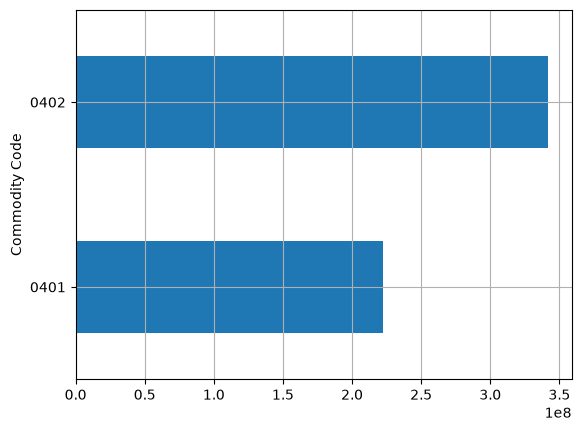

In [ ]:
milk_imports_grouped['Trade Value (US$)'].aggregate(sum).plot(kind='barh')

In [ ]:
monthlies=milk_countries_imports.groupby(['Commodity','Trade Flow','Period'])['Trade Value (US$)'].aggregate(sum)
monthlies

Commodity                                           Trade Flow  Period
Milk and cream, concentrated or sweetened           Imports     201401    30423330
                                                                201402    20614513
                                                                201403    26335257
                                                                201404    24770338
                                                                201405    26409462
                                                                201406    29081876
                                                                201407    25668642
                                                                201408    23360790
                                                                201409    37418160
                                                                201410    38012444
                                                                201411    39465351
                

In [ ]:
from numpy import mean

GROUPING_COMMFLOWPERIOD=['Commodity','Trade Flow','Period']
milk_countries.groupby(GROUPING_COMMFLOWPERIOD)['Trade Value (US$)'].aggregate([sum, min, max, mean])

sum  \
Commodity                                          Trade Flow Period             
Milk and cream, concentrated or sweetened          Exports    201401  40215103   
                                                              201402  32298379   
                                                              201403  42987355   
                                                              201404  52900517   
                                                              201405  55987927   
                                                              201406  59594101   
                                                              201407  33370590   
                                                              201408  35080215   
                                                              201409  27320915   
                                                              201410  30387862   
                                                              201411  23417285   
                                                              201412  31301034   
                                                   Imports    201401  30423330   
                                                              201402  20614513   
                                                              201403  26335257   
                                                              201404  24770338   
                                                              201405  26409462   
                                                              201406  29081876   
                                                              201407  25668642   
                                                              201408  23360790   
                                                              201409  37418160   
                                                              201410  38012444   
                                                              201411  39465351   
                                                              201412  20217008   
Milk and cream, neither concentrated nor sweetened Exports    201401  46923551   
                                                              201402  40191337   
                                                              201403  43794069   
                                                              201404  42295261   
                                                              201405  40213208   
                                                              201406  39721799   
                                                              201407  39508126   
                                                              201408  26657488   
                                                              201409  33279378   
                                                              201410  26615555   
                                                              201411  25876673   
                                                              201412  28714207   
                                                   Imports    201401  21950746   
                                                              201402  18685554   
                                                              201403  17984197   
                                                              201404  19440269   
                                                              201405  21665662   
                                                              201406  16022428   
                                                              201407  19128109   
                                                              201408  16934043   
                                                              201409  19284385   
                                                              201410  18353099   
                                                              201411  17617864   
                                                         

<Axes: ylabel='Commodity Code,Period'>

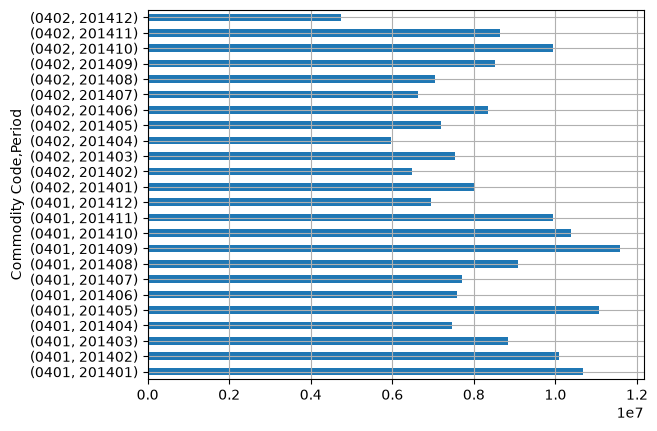

In [ ]:
milk_countries_imports.groupby(['Commodity Code','Period'])['Trade Value (US$)'].aggregate(max).plot(kind='barh')

In [ ]:
milk_bypartner_total=milk[milk["Trade Flow"]=='Imports'].groupby(['Partner'])['Trade Value (US$)'].aggregate(sum)
milk_bypartner_total.head(5)

Partner
Austria         798816
Belgium       58338745
Czech Rep.     1254989
Denmark       30534642
Finland             12
Name: Trade Value (US$), dtype: int64

<Axes: ylabel='Partner'>

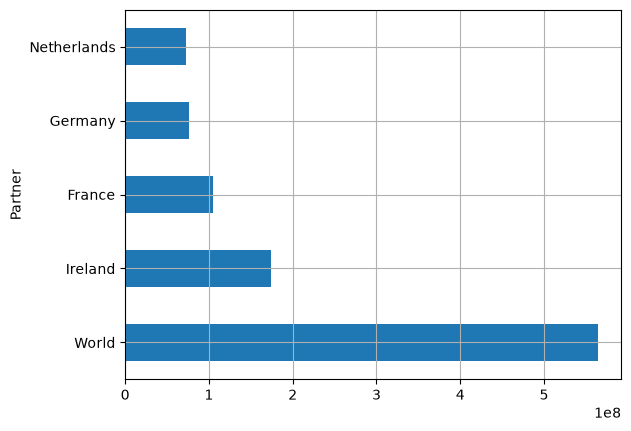

In [ ]:
milk_bypartner_total.sort_values(ascending=False, inplace=False).head(5).plot(kind='barh')

In [ ]:
# Filter for trade item 0402
m0402 = milk_countries[
    milk_countries['Commodity Code'] == '0402'
]

# Calculate monthly mean, maximum and total trade values
stats = (
    m0402
    .groupby(['Trade Flow', 'Period'])['Trade Value (US$)']
    .agg(['mean', 'max', 'sum'])
)

print("Monthly statistics:")
display(stats)

# Find the month with the highest mean, maximum and total
highest_months = (
    stats
    .groupby('Trade Flow')
    .agg({
        'mean': 'idxmax',
        'max': 'idxmax',
        'sum': 'idxmax'
    })
)

print("\nMonths with the highest mean, maximum and total:")
display(highest_months)

Monthly statistics:


mean       max       sum
Trade Flow Period                                  
Exports    201401  6.933638e+05   8908460  40215103
           201402  6.333015e+05   9634586  32298379
           201403  8.266799e+05  11015471  42987355
           201404  1.037265e+06  14875816  52900517
           201405  9.653091e+05  19656679  55987927
           201406  1.045511e+06  22411564  59594101
           201407  5.959034e+05   8430285  33370590
           201408  6.048313e+05   7431534  35080215
           201409  4.793143e+05   5498955  27320915
           201410  4.675056e+05   4074424  30387862
           201411  4.181658e+05   4721974  23417285
           201412  5.491409e+05   6267310  31301034
Imports    201401  2.535278e+06   8020014  30423330
           201402  1.717876e+06   6494426  20614513
           201403  2.025789e+06   7545848  26335257
           201404  1.548146e+06   5956478  24770338
           201405  1.886390e+06   7183954  26409462
           201406  1.938792e+06   8337597  29081876
           201407  1.711243e+06   6630456  25668642
           201408  1.946732e+06   7051096  23360790
           201409  2.338635e+06   8514848  37418160
           201410  2.111802e+06   9941905  38012444
           201411  2.466584e+06   8630781  39465351
           201412  1.555154e+06   4749124  20217008


Months with the highest mean, maximum and total:


,mean,max,sum
Trade Flow,,,
Exports,"(Exports, 201406)","(Exports, 201406)","(Exports, 201406)"
Imports,"(Imports, 201401)","(Imports, 201410)","(Imports, 201411)"


For commodity 0402, June 2014 recorded the highest average, maximum and total export activity. The mean export value was approximately $1.05 million, the maximum was $22.41 million, and the total was $59.59 million. For imports, the results differed across the three measures. January recorded the highest average import value at approximately $2.54 million, October had the highest individual value at approximately $9.94 million, while November recorded the highest total import value at approximately $39.47 million. This demonstrates that the month with the highest average or maximum trade value does not necessarily have the highest overall trade value.

In [ ]:
monthly = (fuel_countries.groupby(['flowDesc', 'period'])['primaryValue']
                         .sum().unstack('flowDesc'))
print(monthly)
print(monthly.idxmax())

flowDesc        Export        Import
period                              
202301    2.547118e+06  2.330129e+09
202302    3.979434e+06  1.877793e+09
202303    1.424582e+06  2.206008e+09
202304    3.543407e+06  1.961744e+09
202305    2.258639e+07  1.649031e+09
202306    1.350737e+07  8.717848e+08
202307    1.466624e+06  1.231934e+09
202308    5.216439e+06  1.703502e+09
202309    1.129980e+07  1.511088e+09
202310    2.591767e+07  1.247052e+09
202311    6.997258e+06  2.126226e+09
202312    1.188479e+07  1.396964e+09
flowDesc
Export    202310
Import    202301
dtype: int64


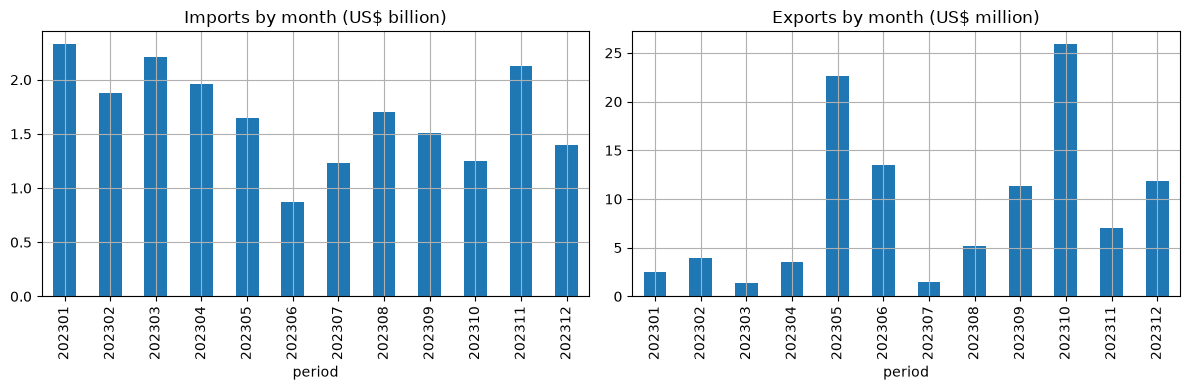

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(monthly['Import'] / 1e9).plot(kind='bar', ax=axes[0], title='Imports by month (US$ billion)')
(monthly['Export'] / 1e6).plot(kind='bar', ax=axes[1], title='Exports by month (US$ million)')
plt.tight_layout()

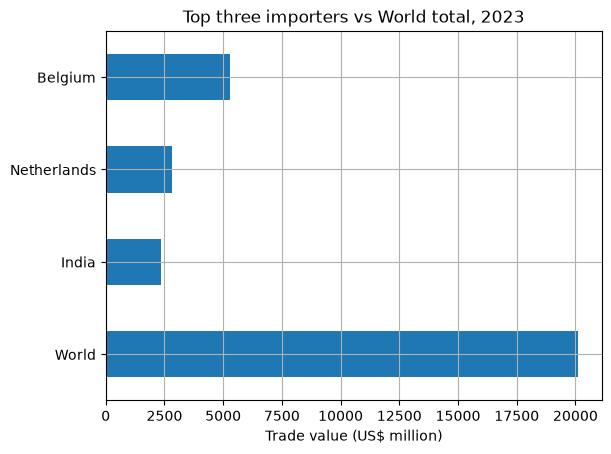

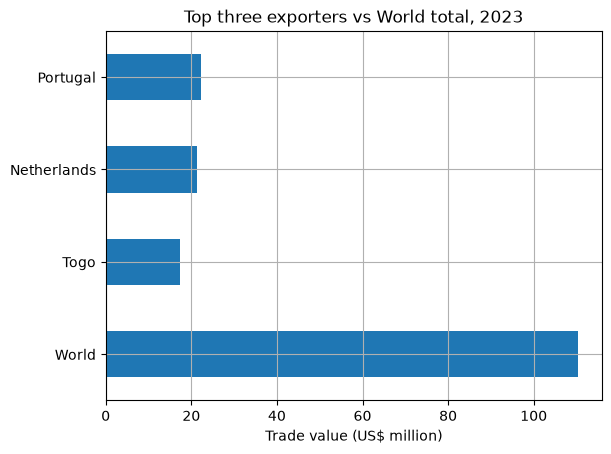

In [ ]:
world_totals = world.groupby('flowDesc')['primaryValue'].sum()

for flow, label in [('Import', 'importers'), ('Export', 'exporters')]:
    top3 = (named[named['flowDesc'] == flow]
            .groupby('partnerDesc')['primaryValue'].sum()
            .sort_values(ascending=False).head(3))
    plot_data = pd.concat([top3, pd.Series({'World': world_totals[flow]})]) / 1e6
    ax = plot_data.plot(kind='barh', title=f'Top three {label} vs World total, 2023')
    ax.set_xlabel('Trade value (US$ million)')
    ax.invert_yaxis()
    plt.show()

**Conclusions**

Nigeria's trade in refined petroleum products (HS 2710) in 2023 was analysed to understand its major import and export partners, the distribution of trade values, and monthly trade activity.

Nigeria's imports were substantially higher than its exports throughout the year. The largest import partners were Belgium (approximately $5.29 billion), the Netherlands ($2.83 billion), India ($2.35 billion), Malta ($1.92 billion) and the Russian Federation ($1.24 billion). This indicates that Nigeria's refined petroleum imports were concentrated among a relatively small number of major trading partners.

For exports, the largest reported partner category was "Areas, nes" at approximately $41.25 million. However, this is a geographical reporting category rather than an individual country. Among identifiable countries, Portugal was the largest export partner (approximately $22.29 million), followed by the Netherlands ($21.42 million) and Togo ($17.47 million).

The Netherlands was among the leading partners for both imports and exports, indicating that Nigeria had trade in both directions with this partner. Belgium, however, was particularly significant for imports.

Monthly trade values also varied considerably. Imports were highest in January 2023, at approximately $2.33 billion, and lowest in June, at approximately $871.78 million. Exports peaked in October at approximately $25.92 million and were lowest in March, at approximately $1.42 million. These fluctuations suggest changes in monthly trade activity, although one year of data is insufficient to establish a recurring seasonal pattern.

Overall, the data shows that Nigeria was a much larger importer than exporter of refined petroleum products in 2023. The concentration of import value among a few major partners and the substantial difference between import and export values are notable findings. However, the results should be interpreted with some caution because the dataset includes reporting categories such as "Areas, nes" and "Other Asia, nes", and its export records are considerably fewer than its import records.

## Conclusions

The milk and cream trade of the UK from January to May 2015 was analysed in terms of which countries the UK mostly depends on for income (exports) and goods (imports). Over the period, the UK had a trade surplus of over 100 million US dollars.

Ireland is the main partner, but it imported from the UK almost the triple in value than it exported to the UK. 

The UK exported to over 100 countries during the period, but only imported from 21 countries, the main ones (top five by trade value) being geographically close. China and Hong Kong are the main importers that are not also main exporters. 

The UK is heavily dependent on its regular customers, the 16 countries that buy all types of milk and cream every month. They contribute three quarters of the total export value.

The UK has bi-directional trade (i.e. both exports and imports) with 20 countries, although for some the trade value (in US dollars) is suspiciously low, which raises questions about the data's accuracy.


## Now repeat the analysis with your own data gotten from Comtrade website

---
# Part B: Data Visualization

Add your seaborn/matplotlib plots below. Use the milk trade data from Part A. Give each plot a title and labelled axes, and write one sentence under it saying what it shows.

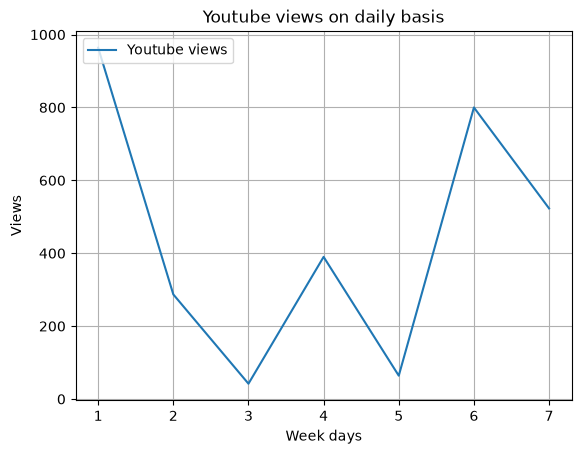

In [ ]:
## Matplotlib

import matplotlib.pyplot as plt

x=[1,2,3,4,5,6,7] # week days
y=[964,287,42,390,64,800,523] # views

plt.plot(x,y,label='Youtube views')
plt.xlabel('Week days')
plt.ylabel('Views')
plt.title('Youtube views on daily basis')
plt.legend(loc='upper left')

plt.show()

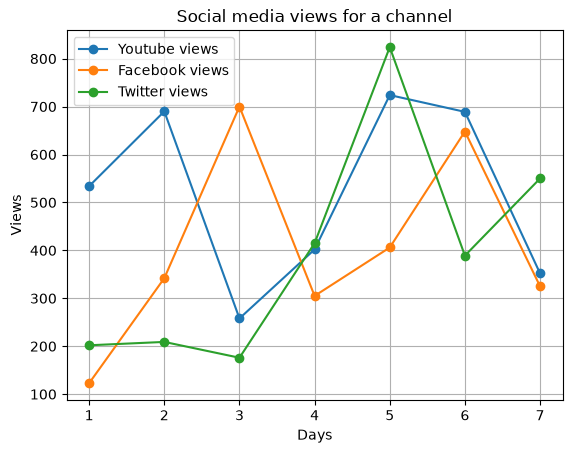

In [ ]:
## Matplotlib Part 3

# Ploting multiple datasets in a single plot

import matplotlib.pyplot as plt

y_views=[534,690,258,402,724,689,352]
f_views=[123,342,700,305,406,648,325]
t_views=[202,209,176,415,824,389,550]
days=[1,2,3,4,5,6,7]

plt.plot(days,y_views,label='Youtube views',marker='o')
plt.plot(days,f_views,label='Facebook views',marker='o')
plt.plot(days,t_views,label='Twitter views',marker='o')

plt.xlabel('Days')
plt.ylabel('Views')
plt.title('Social media views for a channel')
plt.legend()
plt.show()

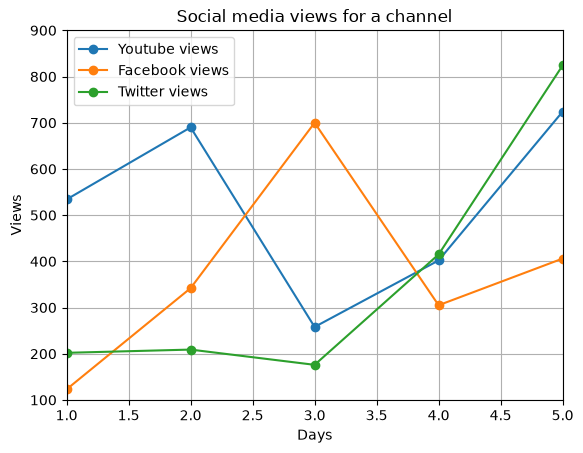

In [ ]:
## Matplotlib Part 4

# Setting of X and Y axis limits

import matplotlib.pyplot as plt

y_views=[534,690,258,402,724,689,352]
f_views=[123,342,700,305,406,648,325]
t_views=[202,209,176,415,824,389,550]
days=[1,2,3,4,5,6,7]

plt.plot(days,y_views,label='Youtube views',marker='o')
plt.plot(days,f_views,label='Facebook views',marker='o')
plt.plot(days,t_views,label='Twitter views',marker='o')
plt.xlabel('Days')
plt.ylabel('Views')
plt.title('Social media views for a channel')
plt.legend()

plt.xlim(1,5)
plt.ylim(100,900)
plt.show()

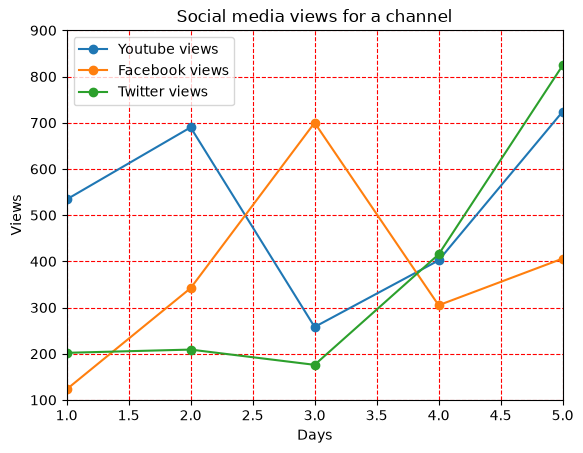

In [ ]:
## Matplotlib Part 5

# Setting up gridlines

import matplotlib.pyplot as plt

y_views=[534,690,258,402,724,689,352]
f_views=[123,342,700,305,406,648,325]
t_views=[202,209,176,415,824,389,550]
days=[1,2,3,4,5,6,7]

plt.plot(days,y_views,label='Youtube views',marker='o')
plt.plot(days,f_views,label='Facebook views',marker='o')
plt.plot(days,t_views,label='Twitter views',marker='o')
plt.xlabel('Days')
plt.ylabel('Views')
plt.title('Social media views for a channel')
plt.legend()

plt.xlim(1,5)
plt.ylim(100,900)

plt.grid(True,color='r',linestyle='--')
plt.show()

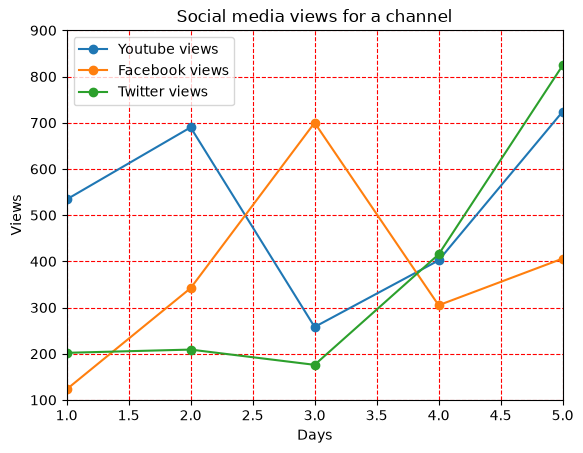

In [ ]:
## Matplotlib Part 6

# saving plots
import matplotlib.pyplot as plt

y_views=[534,690,258,402,724,689,352]
f_views=[123,342,700,305,406,648,325]
t_views=[202,209,176,415,824,389,550]
days=[1,2,3,4,5,6,7]

plt.plot(days,y_views,label='Youtube views',marker='o')
plt.plot(days,f_views,label='Facebook views',marker='o')
plt.plot(days,t_views,label='Twitter views',marker='o')
plt.xlabel('Days')
plt.ylabel('Views')
plt.title('Social media views for a channel')
plt.xlim(1,5)
plt.ylim(100,900)
plt.grid(True,color='r',linestyle='--')
plt.legend()
plt.savefig('img_2.png',dpi=500,facecolor='cyan')
plt.show()

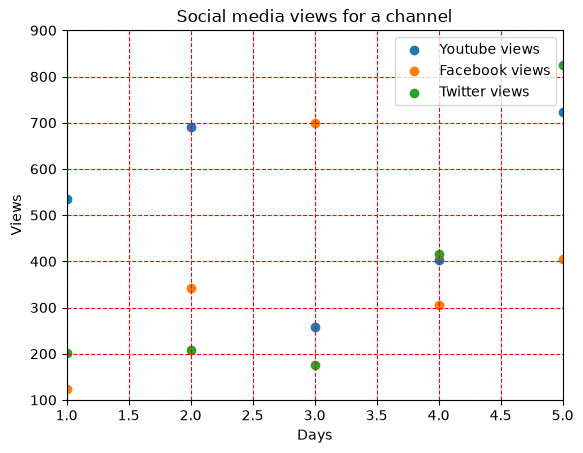

In [ ]:
## Matplotlib Part 7

# Scatter Plots

import matplotlib.pyplot as plt

y_views=[534,690,258,402,724,689,352]
f_views=[123,342,700,305,406,648,325]
t_views=[202,209,176,415,824,389,550]
days=[1,2,3,4,5,6,7]

plt.scatter(days,y_views,label='Youtube views',marker='o')
plt.scatter(days,f_views,label='Facebook views',marker='o')
plt.scatter(days,t_views,label='Twitter views',marker='o')
plt.xlabel('Days')
plt.ylabel('Views')
plt.title('Social media views for a channel')
plt.xlim(1,5)
plt.ylim(100,900)
plt.grid(True,color='r',linestyle='--')
plt.legend()
plt.savefig('img_3.png',dpi=500)
plt.show()

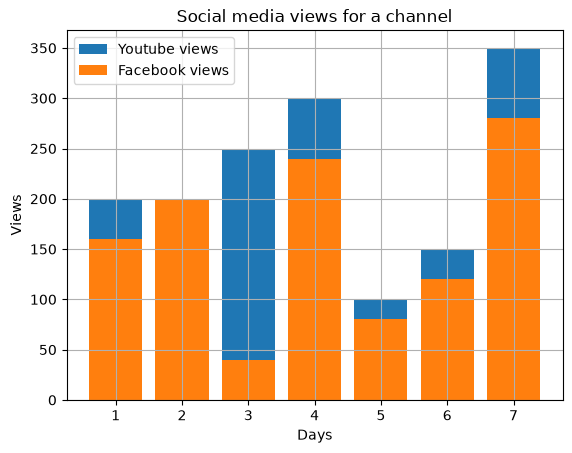

In [ ]:
## Matplotlib Part 8

# Bar Charts

import matplotlib.pyplot as plt

y_views=[200,50,250,300,100,150,350]
fb_views=[160,200,40,240,80,120,280]

days=[1,2,3,4,5,6,7]

plt.bar(days,y_views,label='Youtube views')
plt.bar(days,fb_views,label='Facebook views')

plt.xlabel('Days')
plt.ylabel('Views')
plt.title('Social media views for a channel')
plt.legend()
plt.savefig('bar_2.png',dpi=500)
plt.show()

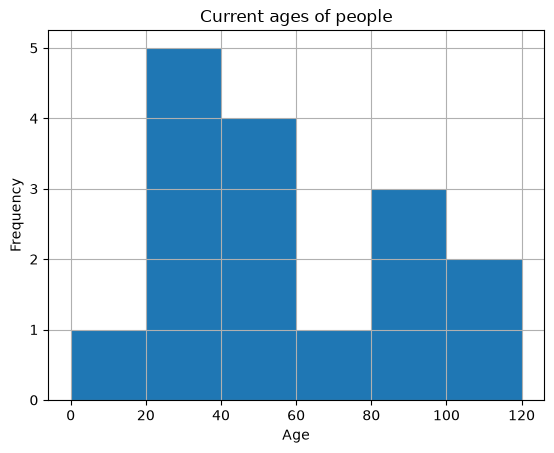

In [ ]:
## Matplotlib Part 9

# Histograms

import matplotlib.pyplot as plt

ages=[22,55,62,45,21,22,99,34,42,4,102,110,27,48,99,84]
bins=[0,20,40,60,80,100,120]

plt.hist(ages,bins)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Current ages of people')
plt.savefig('hist.png',dpi=500)
plt.show()

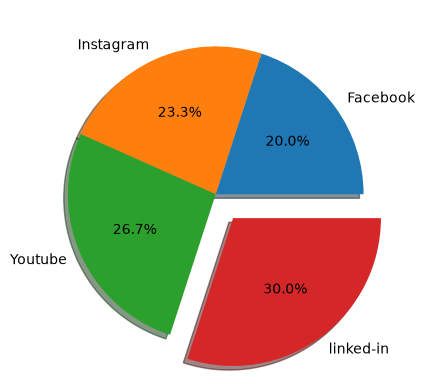

In [ ]:
## Matplotlib Part 10

# Pie Charts

import matplotlib.pyplot as plt

labels_1=['Facebook','Instagram','Youtube','linked-in']
views=[300,350,400,450]
explode_1=[0,0,0,0.2]

plt.pie(views,labels=labels_1,
        autopct='%1.1f%%',
        explode=explode_1,
        shadow=True)
plt.savefig('pie.png',dpi=500)
plt.show()

In [ ]:
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

m = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
m = m[(m['Partner'] != 'World') & (m['Trade Value (US$)'] > 0)].copy()
m['Milk type'] = m['Commodity Code'].map({'0401': 'unprocessed', '0402': 'processed'})
m['log10 value'] = np.log10(m['Trade Value (US$)'])

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

m = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
m = m[(m['Partner'] != 'World') & (m['Trade Value (US$)'] > 0)].copy()
m['Milk type'] = m['Commodity Code'].map({'0401': 'unprocessed', '0402': 'processed'})
m['log10 value'] = np.log10(m['Trade Value (US$)'])   # values are very skewed, so use a log scale

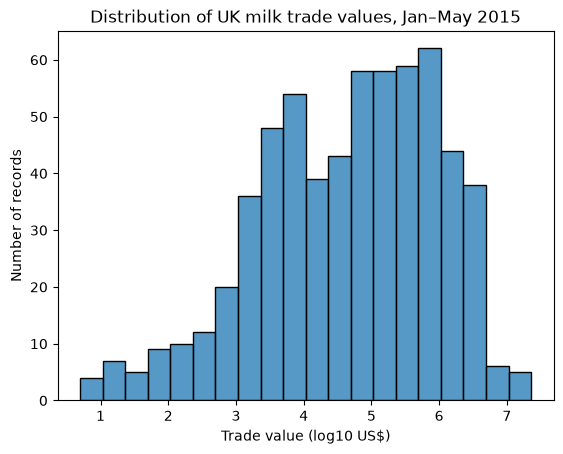

In [ ]:
sns.histplot(data=m, x='log10 value', bins=20)
plt.title('Distribution of UK milk trade values, Jan–May 2015')
plt.xlabel('Trade value (log10 US$)'); plt.ylabel('Number of records')
plt.show()

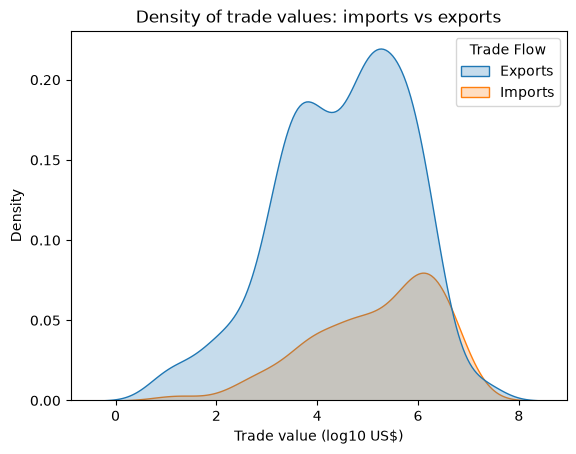

In [ ]:
sns.kdeplot(data=m, x='log10 value', hue='Trade Flow', fill=True)
plt.title('Density of trade values: imports vs exports')
plt.xlabel('Trade value (log10 US$)'); plt.ylabel('Density')
plt.show()

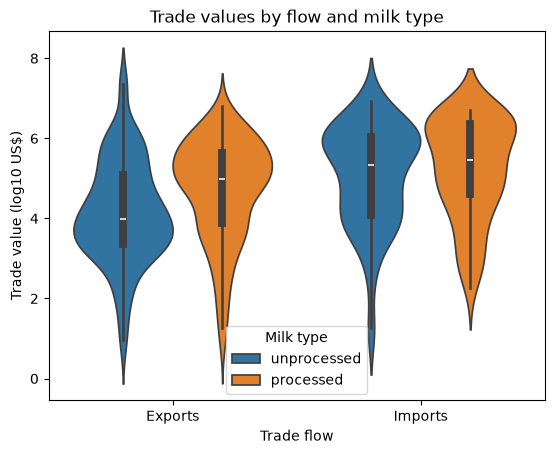

In [ ]:
sns.violinplot(data=m, x='Trade Flow', y='log10 value', hue='Milk type', split=False)
plt.title('Trade values by flow and milk type')
plt.xlabel('Trade flow'); plt.ylabel('Trade value (log10 US$)')
plt.show()

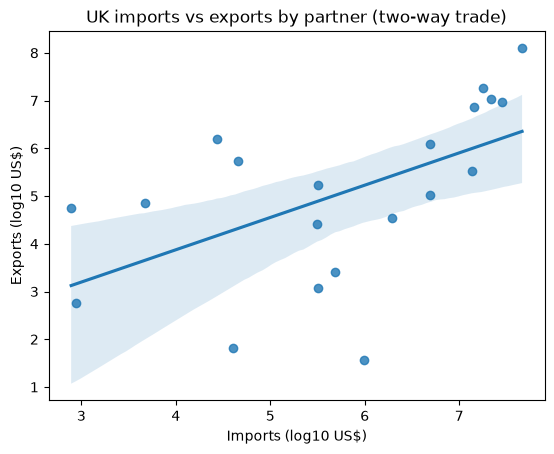

In [ ]:
both = (m.pivot_table(index='Partner', columns='Trade Flow',
                      values='Trade Value (US$)', aggfunc='sum').dropna())
both = np.log10(both)
sns.regplot(data=both, x='Imports', y='Exports')
plt.title('UK imports vs exports by partner (two-way trade)')
plt.xlabel('Imports (log10 US$)'); plt.ylabel('Exports (log10 US$)')
plt.show()

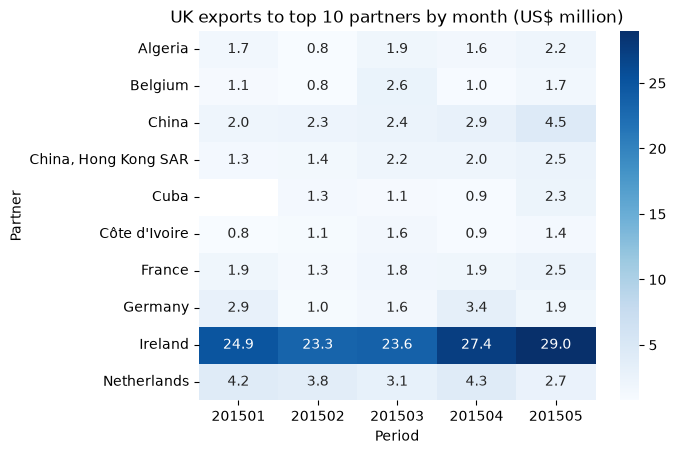

In [ ]:
ex = m[m['Trade Flow'] == 'Exports']
top10 = ex.groupby('Partner')['Trade Value (US$)'].sum().nlargest(10).index
grid = (ex[ex['Partner'].isin(top10)]
        .pivot_table(index='Partner', columns='Period',
                     values='Trade Value (US$)', aggfunc='sum') / 1e6)
sns.heatmap(grid, annot=True, fmt='.1f', cmap='Blues')
plt.title('UK exports to top 10 partners by month (US$ million)')
plt.xlabel('Period'); plt.ylabel('Partner')
plt.show()

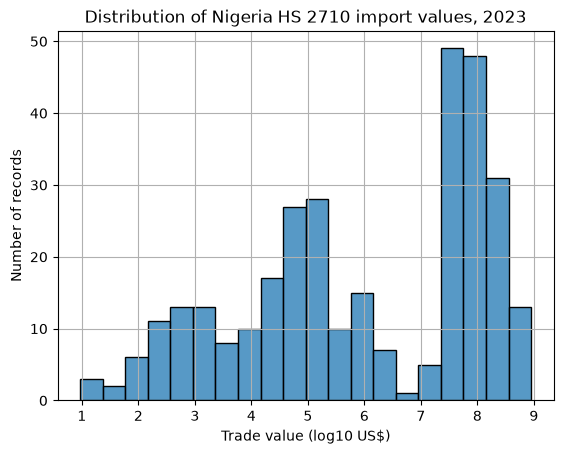

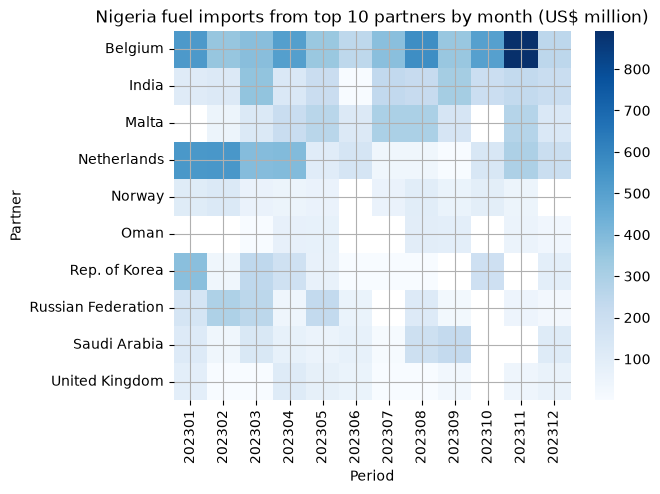

In [87]:
f = fuel_countries[fuel_countries['primaryValue'] > 0].copy()
f['log10 value'] = np.log10(f['primaryValue'])

# Histogram of import values
sns.histplot(data=f[f['flowDesc'] == 'Import'], x='log10 value', bins=20)
plt.title('Distribution of Nigeria HS 2710 import values, 2023')
plt.xlabel('Trade value (log10 US$)'); plt.ylabel('Number of records')
plt.show()

# Heatmap: top 10 import partners by month
imp = f[f['flowDesc'] == 'Import']
top10 = imp.groupby('partnerDesc')['primaryValue'].sum().nlargest(10).index
grid = (imp[imp['partnerDesc'].isin(top10)]
        .pivot_table(index='partnerDesc', columns='period',
                     values='primaryValue', aggfunc='sum') / 1e6)
sns.heatmap(grid, cmap='Blues')
plt.title('Nigeria fuel imports from top 10 partners by month (US$ million)')
plt.xlabel('Period'); plt.ylabel('Partner')
plt.show()

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you split, applied and combined the UK milk-trade data with `groupby` and `pivot_table`, then plotted it. Now answer the same kind of questions **in SQL**, straight from the `week09` tables: `GROUP BY` is SQL's split-apply-combine.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [ ]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   4,
   4
  ],
  "58c6ed3aa1049eff4acfe5edcb59b1d51d4a45f3579bb7c1db90ae2724f0e865"
 ],
 "s02": [
  [
   12,
   4
  ],
  "cf8e205c894ca889a22c89cfce94e601860d25931f62e999f4408800c74d8280"
 ],
 "s03": [
  [
   10,
   3
  ],
  "d6dcb9773bc969b74418a8b0a4bcc92581bf839100b25d7b16d2710934ca53d8"
 ],
 "s04": [
  [
   6,
   5
  ],
  "d940a4dfa48898fdeea545a6f4a693d039a8601cb0ad38d9f20bab0e641840d1"
 ],
 "s05": [
  [
   30,
   4
  ],
  "92f2c46acfb66aa693f51c79b678dbfed4d60714ebfb6c6a3a5d08e585879061"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Split-apply-combine: GROUP BY two columns",
 "s02": "A monthly imports vs exports table",
 "s03": "Subtotals with GROUPING SETS",
 "s04": "Top 3 partners per trade flow (window function)",
 "s05": "A tidy table for a stacked bar chart"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Split-apply-combine: GROUP BY two columns

Use the 2015 data, `week09.comtrade_milk_uk_jan_jul_15` (it covers January–May 2015). Group it by **trade flow** and
**milk type**, like the lesson's `milk.groupby([FLOW, COMMODITY])`. The milk type comes from the commodity code:
`'0401'` → `'unprocessed'`, `'0402'` → `'processed'`.

**Return:** `trade_flow`, `milk_type`, `partners` (how many **different** partner countries), `total_musd` (total
trade value in **millions** of US$, **rounded to 2 dp**). Sort by `trade_flow`, then `milk_type` (both A→Z).
⚠️ Remove the `Partner = 'World'` rows first: they are monthly totals, so keeping them counts everything twice.
💡 `CASE [Commodity Code] WHEN '0401' THEN ... END`, `COUNT(DISTINCT Partner)`, and `GROUP BY` the same `CASE`
expression.

In [ ]:
SQL_01 = """
SELECT [Trade Flow] AS trade_flow,
       CASE [Commodity Code]
           WHEN '0401' THEN 'unprocessed'
           WHEN '0402' THEN 'processed'
           ELSE 'unknown'
       END AS milk_type,
       COUNT(DISTINCT Partner) AS partners,
       ROUND(SUM([Trade Value (US$)]) / 1000000.0, 2) AS total_musd
FROM week09.comtrade_milk_uk_jan_jul_15
WHERE Partner <> 'World'
  AND [Commodity Code] IN ('0401', '0402')
GROUP BY [Trade Flow],
         CASE [Commodity Code]
             WHEN '0401' THEN 'unprocessed'
             WHEN '0402' THEN 'processed'
             ELSE 'unknown'
         END
ORDER BY trade_flow, milk_type;
"""

p.sql("s01", SQL_01)

,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


✅ s01: correct!


,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


### SQL Task 2 · A monthly imports vs exports table

`week09.countrymilk` is the clean 2014 data: one row per month, flow, partner and commodity, with the
`'World'` rows already removed. Build the table that `pivot_table(index='Period', columns='Trade Flow', ...)` gives you,
but in SQL: **one row per month**, imports and exports side by side, plus the trade balance.

**Return:** `period` (e.g. `201401`), `imports_musd`, `exports_musd`, `balance_musd` (exports − imports), all in
**millions of US$, rounded to 2 dp**. Sort by `period`.
⚠️ Work out the balance from the **unrounded** sums and round only at the end (rounding first can be 0.01 off).
💡 Conditional aggregation: `SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)`. `PIVOT`
works too. Look at the result: is the balance positive in every month?

In [ ]:
SQL_02 = """
SELECT Period AS period,
       ROUND(SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END) / 1000000.0, 2) AS imports_musd,
       ROUND(SUM(CASE WHEN [Trade Flow] = 'Exports' THEN [Trade Value (US$)] ELSE 0 END) / 1000000.0, 2) AS exports_musd,
       ROUND((SUM(CASE WHEN [Trade Flow] = 'Exports' THEN [Trade Value (US$)] ELSE 0 END)
            - SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)) / 1000000.0, 2) AS balance_musd
FROM week09.countrymilk
GROUP BY Period
ORDER BY Period
"""
p.sql("s02", SQL_02)

,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


✅ s02: correct!


,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


### SQL Task 3 · Subtotals with GROUPING SETS

A manager wants a **quarterly report for 2014** (`week09.countrymilk`) with a **year subtotal** under each trade
flow, in one query.

**Return:** `trade_flow`, `quarter` (`'Q1'` … `'Q4'`, or `'Year'` on the subtotal row), `total_musd` (millions of
US$, **rounded to 2 dp**). That is 10 rows: for each flow, Q1–Q4 and then its `'Year'` row. Sort by `trade_flow`
(A→Z), then the quarters in order, with the `'Year'` row last.
💡 Quarter from `Period`: `(Period % 100 + 2) / 3` gives 1–4 (integer division). Then
`GROUP BY GROUPING SETS ((flow, quarter), (flow))`, and `GROUPING(quarter) = 1` tells you a row is a subtotal.
⚠️ Don't add a grand total over both flows: adding imports to exports is not a meaningful number.

In [ ]:
SQL_03 = """
WITH q AS (
    SELECT [Trade Flow] AS trade_flow,
           (CAST(Period AS int) % 100 + 2) / 3 AS qn,
           [Trade Value (US$)] AS v
    FROM week09.countrymilk
)
SELECT trade_flow,
       CASE WHEN GROUPING(qn) = 1 THEN 'Year'
            ELSE 'Q' + CAST(qn AS varchar(1)) END AS quarter,
       ROUND(SUM(v) / 1000000.0, 2) AS total_musd
FROM q
GROUP BY GROUPING SETS ((trade_flow, qn), (trade_flow))
ORDER BY trade_flow, GROUPING(qn), qn
"""
p.sql("s03", SQL_03)

,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


✅ s03: correct!


,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


### SQL Task 4 · Top 3 partners per trade flow (window function)

Project 4 asks: *which are the main trading partners?* Answer it for **both flows at once** using 2014
(`week09.countrymilk`): the **top 3 partners by total trade value in each trade flow**, and each partner's share of
that flow's total.

**Return:** `trade_flow`, `rank` (1–3), `partner`, `total_musd` (millions of US$, **rounded to 2 dp**), `share_pct`
(the partner's % of **its flow's** total over all partners, **rounded to 1 dp**). Sort by `trade_flow`, then `rank`.
💡 First total per (flow, partner) in a CTE. Then `ROW_NUMBER() OVER (PARTITION BY flow ORDER BY total DESC,
partner)` and `SUM(total) OVER (PARTITION BY flow)` for the share. Filter `rank <= 3` in the outer query (you can't
filter on a window function in the same `WHERE`).

In [ ]:
SQL_04 = """
WITH t AS (
    SELECT [Trade Flow] AS trade_flow, Partner AS partner,
           SUM([Trade Value (US$)]) AS total
    FROM week09.countrymilk
    GROUP BY [Trade Flow], Partner
),
r AS (
    SELECT trade_flow, partner, total,
           ROW_NUMBER() OVER (PARTITION BY trade_flow ORDER BY total DESC, partner) AS rnk,
           SUM(total) OVER (PARTITION BY trade_flow) AS flow_total
    FROM t
)
SELECT trade_flow, rnk AS [rank], partner,
       ROUND(total / 1000000.0, 2) AS total_musd,
       ROUND(100.0 * total / flow_total, 1) AS share_pct
FROM r
WHERE rnk <= 3
ORDER BY trade_flow, rnk
"""
p.sql("s04", SQL_04)

,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


✅ s04: correct!


,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


### SQL Task 5 · A tidy table for a stacked bar chart

For **Part B** you want a stacked bar chart of the UK's **2015 exports** (`week09.comtrade_milk_uk_jan_jul_15`):
one bar per month, split into the **5 biggest export partners** plus one `'Other'` slice for everyone else. Seaborn
likes **tidy (long)** data: one row per month and partner group. Build that table in SQL.

The "top 5" are the 5 partners with the largest **total** exports over all five months (ties: partner A→Z). Every
other partner becomes `'Other'`.

**Return:** `period`, `partner_group`, `exports_musd` (millions of US$, **rounded to 2 dp**), `share_pct` (the group's
% of **that month's** exports, **rounded to 1 dp**). 30 rows. Sort by `period`, then `partner_group` A→Z but with
`'Other'` last in each month.
⚠️ Exports only, and no `'World'` rows.
💡 CTE 1: the export rows. CTE 2: `SELECT TOP 5 Partner ... GROUP BY Partner ORDER BY SUM(...) DESC, Partner`.
`LEFT JOIN` the rows to the top 5 and use `CASE` to label the rest `'Other'`. For the share:
`SUM(SUM(v)) OVER (PARTITION BY period)` (a window over a grouped result).

In [ ]:
SQL_05 = """
WITH e AS (
    SELECT Period, Partner, [Trade Value (US$)] AS v
    FROM week09.comtrade_milk_uk_jan_jul_15
    WHERE [Trade Flow] = 'Exports' AND Partner <> 'World'
),
top5 AS (
    SELECT TOP 5 Partner
    FROM e
    GROUP BY Partner
    ORDER BY SUM(v) DESC, Partner
),
g AS (
    SELECT e.Period,
           CASE WHEN t.Partner IS NULL THEN 'Other' ELSE e.Partner END AS partner_group,
           SUM(e.v) AS v
    FROM e
    LEFT JOIN top5 t ON e.Partner = t.Partner
    GROUP BY e.Period,
             CASE WHEN t.Partner IS NULL THEN 'Other' ELSE e.Partner END
)
SELECT Period AS period, partner_group,
       ROUND(v / 1000000.0, 2) AS exports_musd,
       ROUND(100.0 * v / SUM(v) OVER (PARTITION BY Period), 1) AS share_pct
FROM g
ORDER BY Period,
         CASE WHEN partner_group = 'Other' THEN 1 ELSE 0 END,
         partner_group
"""
p.sql("s05", SQL_05)

,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


✅ s05: correct!


,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


### Practice score
Run this when you're done.

In [ ]:
p.score()

Task Type                                           Topic Result
 s01  SQL       Split-apply-combine: GROUP BY two columns      ✅
 s02  SQL              A monthly imports vs exports table      ✅
 s03  SQL                    Subtotals with GROUPING SETS      ✅
 s04  SQL Top 3 partners per trade flow (window function)      ✅
 s05  SQL            A tidy table for a stacked bar chart      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Split-apply-combine: GROUP BY two columns,✅
1,s02,SQL,A monthly imports vs exports table,✅
2,s03,SQL,Subtotals with GROUPING SETS,✅
3,s04,SQL,Top 3 partners per trade flow (window function),✅
4,s05,SQL,A tidy table for a stacked bar chart,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).